In [1]:
from pathlib import Path
import json, inspect, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from astropy.stats import SigmaClip, sigma_clipped_stats
from astropy.convolution import convolve_fft
from astropy.visualization import ZScaleInterval
from astropy.modeling import models, fitting
from photutils.background import Background2D, MedianBackground, StdBackgroundRMS
from photutils.segmentation import detect_sources, deblend_sources, make_2dgaussian_kernel, SourceCatalog
from photutils.utils import calc_total_error
from scipy import ndimage

warnings.filterwarnings("ignore")
DATA, RES, FIG = Path(".."), Path("results"), Path("figures")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.size": 11,
                     "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9})

with fits.open(DATA / "mosaic.fits") as hdul:
    data = hdul[0].data.astype(float); header = hdul[0].header
mask = fits.getdata(RES / "mask.fits").astype(bool)
GAIN = float(header.get("GAIN", 3.1))          # electrons per count
ZP_LAB = float(header["MAGZPT"])               # lab-script zero point (uncalibrated magnitudes)
PIX = float(header.get("PIXSCAL1", 0.258))     # arcsec per pixel

In [2]:
BKG_BOX, BKG_FILTER, BKG_SIGMA_CLIP = (100, 100), (5, 5), 3.0
KERNEL_FWHM_PX, KERNEL_SIZE = 4.0, 9         # smoothing kernel ~ the stellar FWHM
DETECT_NSIGMA, DETECT_NPIXELS = 4.0, 8       # 4 sigma, at least 8 connected pixels
DEBLEND_NLEVELS, DEBLEND_CONTRAST = 32, 0.005
NEAR_MASK_PX = 3


def kw(func, **kwargs):
    """Pass arguments under the names this photutils version uses (n_pixels vs npixels etc.)."""
    params = inspect.signature(func).parameters
    alias = {"n_pixels": "npixels", "n_levels": "nlevels"}
    return {(k if k in params else alias[k]): v for k, v in kwargs.items() if k in params or alias.get(k) in params}


def get_col(cat, *names):
    """Read a SourceCatalog column under whichever name this photutils version uses."""
    for n in names:
        if hasattr(type(cat), n):
            v = getattr(cat, n)
            return np.asarray(getattr(v, "value", v), float)
    raise AttributeError(names)

In [3]:
def background(data, mask):
    b = Background2D(data, BKG_BOX, filter_size=BKG_FILTER, mask=mask, sigma_clip=SigmaClip(sigma=BKG_SIGMA_CLIP),
                     bkg_estimator=MedianBackground(), bkgrms_estimator=StdBackgroundRMS())
    return b.background, b.background_rms


def detect(data, mask, bkg, rms, gain=GAIN):
    """Return (catalogue table, segmentation map, convolved image, filter-noise ratio)."""
    data_sub = data - bkg
    kernel = make_2dgaussian_kernel(KERNEL_FWHM_PX, size=KERNEL_SIZE)
    conv = convolve_fft(np.where(mask, 0.0, data_sub), kernel, normalize_kernel=True, allow_huge=True)
    good = ~mask & (rms > 0)
    ratio = float(sigma_clipped_stats(conv[good] / rms[good], sigma=3.0, maxiters=10)[2])  # noise after smoothing
    segm = detect_sources(conv, DETECT_NSIGMA * ratio * rms, mask=mask, **kw(detect_sources, n_pixels=DETECT_NPIXELS))
    if segm is None:
        return Table(names=["label", "x", "y", "flux"]), np.zeros(data.shape, int), conv, ratio
    extra = {"progress_bar": False} if "progress_bar" in inspect.signature(deblend_sources).parameters else {}
    segm = deblend_sources(conv, segm, contrast=DEBLEND_CONTRAST,
                           **kw(deblend_sources, n_pixels=DETECT_NPIXELS, n_levels=DEBLEND_NLEVELS), **extra)
    cat = SourceCatalog(data_sub, segm, error=calc_total_error(data_sub, rms, gain), mask=mask, convolved_data=conv)
    t = Table()
    t["label"] = get_col(cat, "label").astype(int)
    t["x"] = get_col(cat, "x_centroid", "xcentroid"); t["y"] = get_col(cat, "y_centroid", "ycentroid")
    t["area"] = get_col(cat, "area"); t["flux"] = get_col(cat, "segment_flux")
    t["flux_err"] = get_col(cat, "segment_flux_err", "segment_fluxerr"); t["peak"] = get_col(cat, "max_value")
    t["fwhm"] = get_col(cat, "fwhm"); t["ellipticity"] = get_col(cat, "ellipticity")
    t["a"] = get_col(cat, "semimajor_axis", "semimajor_sigma"); t["b"] = get_col(cat, "semiminor_axis", "semiminor_sigma")
    t["theta"] = get_col(cat, "orientation")
    t["snr"] = t["flux"] / t["flux_err"]
    near = ndimage.binary_dilation(mask, iterations=NEAR_MASK_PX)
    t["near_mask"] = np.isin(t["label"], np.unique(segm.data[near & (segm.data > 0)]))
    t["local_rms"] = rms[np.clip(np.round(t["y"]).astype(int), 0, data.shape[0] - 1),
                         np.clip(np.round(t["x"]).astype(int), 0, data.shape[1] - 1)]
    return t, segm.data, conv, ratio

In [4]:
bkg, rms = background(data, mask)
cat, segm, conv, ratio = detect(data, mask, bkg, rms)
with np.errstate(divide="ignore", invalid="ignore"):
    cat["mag_lab"] = ZP_LAB - 2.5 * np.log10(cat["flux"])     # lab eq. 5, NOT yet calibrated
cat.write(RES / "catalogue.ecsv", overwrite=True)
fits.PrimaryHDU(segm.astype(np.int32)).writeto(RES / "segmentation.fits", overwrite=True)
fits.HDUList([fits.PrimaryHDU(bkg), fits.ImageHDU(rms)]).writeto(
    RES / "background.fits", overwrite=True)
good_px = int((~mask).sum()); area_deg2 = good_px * (PIX / 3600) ** 2
print(f"{len(cat)} sources detected over {area_deg2:.4f} deg^2 of unmasked sky; "
      f"median background noise {np.median(rms[~mask]):.1f} counts")

5917 sources detected over 0.0439 deg^2 of unmasked sky; median background noise 8.8 counts


In [5]:
neg = 2 * bkg - data
neg_cat, _, _, _ = detect(neg, mask, bkg, rms)
print(f"negative image: {len(neg_cat)} false detections = {100 * len(neg_cat) / len(cat):.2f}% of the real catalogue")

negative image: 18 false detections = 0.30% of the real catalogue


In [6]:
sel = cat[(cat["snr"] > 80) & ~cat["near_mask"] & (cat["ellipticity"] < 0.1) & (cat["peak"] < 20000)]
sel.sort("fwhm")
gy, gx = np.mgrid[-12:13, -12:13]
fw = []
for row in sel[:40]:
    x, y = int(round(row["x"])), int(round(row["y"]))
    cut = data[y - 12:y + 13, x - 12:x + 13]
    if cut.shape != gx.shape:
        continue
    model = models.Gaussian2D(cut.max() - np.median(cut), 0, 0, 2, 2) + models.Const2D(np.median(cut))
    p = fitting.LevMarLSQFitter()(model, gx, gy, cut)
    fw.append(2.3548 * np.sqrt(abs(p.x_stddev_0 * p.y_stddev_0)))
fwhm_px = float(np.median(fw))
print(f"stellar FWHM = {fwhm_px:.2f} px = {fwhm_px * PIX:.2f} arcsec (from {len(fw)} stars)")
json.dump({"n_sources": len(cat), "area_deg2": area_deg2, "n_negative": len(neg_cat), "filter_noise_ratio": ratio,
           "fwhm_px": fwhm_px, "fwhm_arcsec": fwhm_px * PIX}, open(RES / "detect_summary.json", "w"), indent=1)

stellar FWHM = 5.24 px = 1.35 arcsec (from 40 stars)


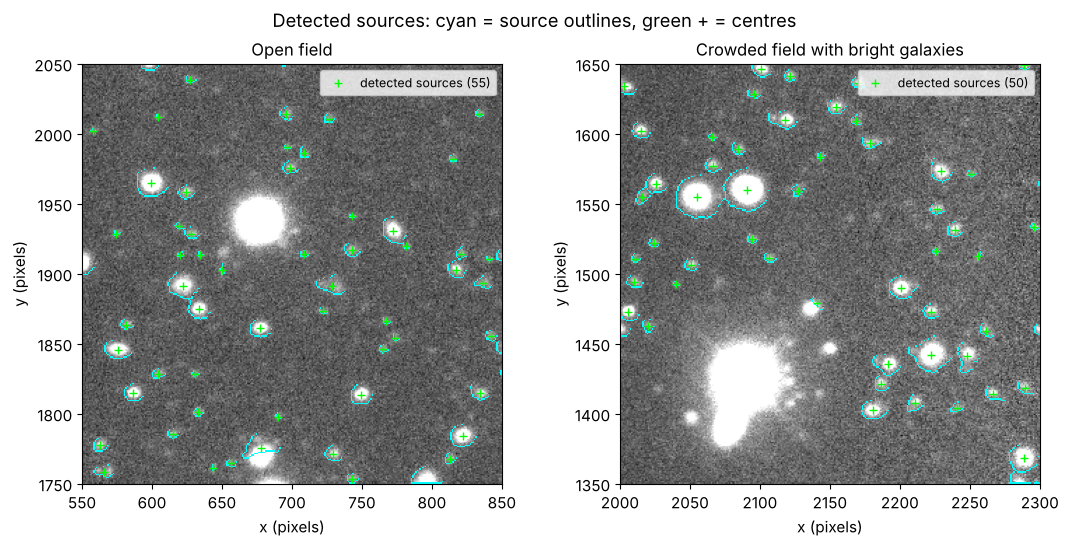

In [7]:
vmin, vmax = ZScaleInterval().get_limits(data[~mask])
fig, axes = plt.subplots(1, 2, figsize=(11, 5.4))
for ax, (xc, yc, title) in zip(axes, [(700, 1900, "Open field"), (2150, 1500, "Crowded field with bright galaxies")]):
    h = 150; x0, x1, y0, y1 = xc - h, xc + h, yc - h, yc + h
    ax.imshow(data[y0:y1, x0:x1], origin="lower", cmap="gray", vmin=vmin, vmax=vmax, extent=[x0, x1, y0, y1])
    s = segm[y0:y1, x0:x1]
    edges = (s > 0) & ((np.roll(s, 1, 0) != s) | (np.roll(s, 1, 1) != s))
    ax.imshow(np.ma.masked_where(~edges, edges), origin="lower", cmap="cool", extent=[x0, x1, y0, y1], interpolation="nearest")
    inb = (cat["x"] > x0) & (cat["x"] < x1) & (cat["y"] > y0) & (cat["y"] < y1)
    ax.plot(cat["x"][inb], cat["y"][inb], "+", color="lime", ms=6, label=f"detected sources ({inb.sum()})")
    ax.set_title(title); ax.set_xlabel("x (pixels)"); ax.set_ylabel("y (pixels)"); ax.legend(loc="upper right")
fig.suptitle("Detected sources: cyan = source outlines, green + = centres")
fig.tight_layout(); fig.savefig(FIG / "02_detection_cutouts.png"); plt.show()

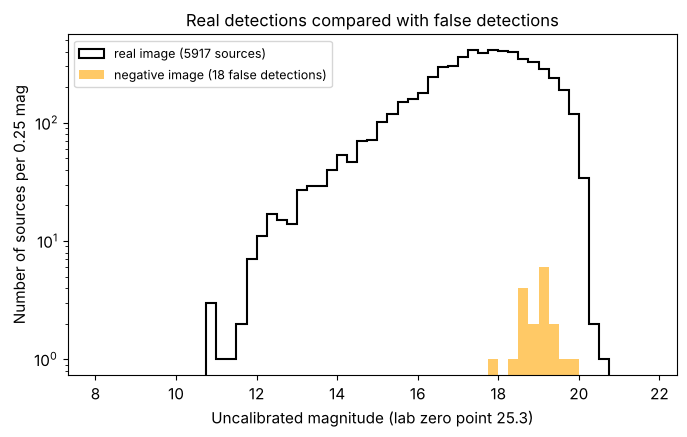

In [8]:
bins = np.arange(8, 22, 0.25)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(cat["mag_lab"], bins, histtype="step", lw=1.5, color="k", label=f"real image ({len(cat)} sources)")
ax.hist(ZP_LAB - 2.5 * np.log10(np.asarray(neg_cat["flux"])), bins, histtype="stepfilled", alpha=0.6, color="orange",
        label=f"negative image ({len(neg_cat)} false detections)")
ax.set_yscale("log"); ax.set_xlabel("Uncalibrated magnitude (lab zero point 25.3)")
ax.set_ylabel("Number of sources per 0.25 mag"); ax.set_title("Real detections compared with false detections")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "02_negative_image_test.png"); plt.show()